# Домашнее задание 4. Линейный поиск и производные

**Выдано:** 28 октября 2026. **Срок сдачи:** 11 ноября 2026 (до начала занятия). **Максимум:** 10 баллов (+2 бонус).

**Главная идея.** Вдали от решения шаг Ньютона может увести куда угодно: квадратичная модель $m(p)=f(x)+g^\top p+\frac12p^\top Hp$ (здесь $g=\nabla f(x)$ — градиент, $H=\nabla^2f(x)$ — гессиан, $p$ — вектор шага) похожа на функцию только рядом с точкой $x$. Лекция 6 даёт лекарство: проверить шаг самой функцией и укоротить его — линейный поиск, задача 1 (второе лекарство, доверительная область, — в бонусе). Задача 2 — откуда берутся сами производные: две теоретические задачи по лекции 7, без кода.

**Как сдавать.** Работа сдаётся в ваш личный закрытый репозиторий `optimisation-misis-2026/numopt-<ваш логин>`; этот ноутбук уже лежит там как `hw4/homework.ipynb`. Код пишите в ячейках с `# TODO`, ответы — в markdown-ячейках вместо `_Ваш ответ:_ TODO`: 2–4 предложения с числами из ваших выводов, в задаче 2 — таблицы. Выполните ноутбук целиком (`Kernel → Restart Kernel and Run All Cells`) и загрузите в папку `hw4/` под тем же именем — пошагово в [инструкции](https://github.com/IlyaChichkanov/Numerical-Optimization/blob/main/CONTRIBUTING.md). Задачи можно обсуждать, но текст и код пишутся самостоятельно; своё решение никому не показывайте.

**Материал:** лекция 6 ([конспект](https://github.com/IlyaChichkanov/Numerical-Optimization/blob/main/lectures/lecture06/lecture06.md), [демо](https://github.com/IlyaChichkanov/Numerical-Optimization/blob/main/lectures/lecture06/demo06.ipynb), [семинар](https://github.com/IlyaChichkanov/Numerical-Optimization/blob/main/lectures/lecture06/seminar06.ipynb)) — задача 1 и бонус; лекция 7 ([конспект](https://github.com/IlyaChichkanov/Numerical-Optimization/blob/main/lectures/lecture07/lecture07.md)) — задача 2. Ничего сверх лекций не требуется. Ориентировочное время — полтора часа, бонус — ещё около получаса.

**Устройство задания.** Функции, их производные (градиент и гессиан построены CasADi — см. `casadi_derivatives` в ячейке ниже), метод Ньютона и рисовальщики даны готовыми. В задаче 1 вы пишете одну короткую функцию `armijo`; под ней стоит проверка `assert` на числах конспекта: прошла — можно идти дальше. Задача 2 решается на бумаге, ответы — таблицы и числа в markdown; готовая ячейка с CasADi показывает, с чем сверяться.

Запуск: в Google Colab первая ячейка сама поставит CasADi; локально — `uv sync --group casadi` в корне клона репозитория курса, затем `uv run jupyter lab`.

In [1]:
import importlib.util, subprocess, sys
if importlib.util.find_spec("casadi") is None:          # Colab: поставить CasADi один раз
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "casadi"], check=True)

import casadi as ca
import numpy as np
import matplotlib.pyplot as plt

BLUE, ORANGE, AQUA, YELLOW, RED, VIOLET, GRAY, INK = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e34948", "#4a3aa7", "#8a8985", "#0b0b0b"
COLORS = [BLUE, ORANGE, AQUA, VIOLET]      # цвета путей по порядку: первый — синий, второй — оранжевый, ...
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.2, "legend.frameon": False})


# ---------------------------------------------------------------- производные — через CasADi (лекция 7)
def casadi_derivatives(expr, x):
    """Из символьного выражения expr(x) — три numpy-функции: f, grad, hess. Градиент и гессиан строит CasADi
    алгоритмическим дифференцированием (обратный режим, лекция 7 §4): формул руками нет, шага h нет."""
    F = ca.Function("f", [x], [expr]); G = ca.Function("g", [x], [ca.gradient(expr, x)])
    H = ca.Function("h", [x], [ca.hessian(expr, x)[0]])
    return (lambda v: float(F(v)), lambda v: np.array(G(v)).ravel(), lambda v: np.array(H(v)))


# ---------------------------------------------------------------- задача 1: функция «косинусная долина», x = (u, v)
_x = ca.SX.sym("x", 2)
f_valley, grad_valley, hess_valley = casadi_derivatives(                      # f(u, v) = 1/2 (u - 1)^2 + 1/2 v^2 + 5/2 (v - cos u)^2
    0.5 * (_x[0] - 1) ** 2 + 0.5 * _x[1] ** 2 + 2.5 * (_x[1] - ca.cos(_x[0])) ** 2, _x)
X0_VALLEY = np.array([0.0, 10.0])            # старт
X_STAR_VALLEY = np.array([1.2496, 0.2631])   # минимум (для звёздочки на картинке)
F_STAR_VALLEY = 0.07267829190755               # значение f в минимуме (1.24961821, 0.26307054)


# ---------------------------------------------------------------- Розенброк (как в лекциях)
rosen, rosen_grad, rosen_hess = casadi_derivatives((1 - _x[0]) ** 2 + 100 * (_x[1] - _x[0] ** 2) ** 2, _x)
X0_ROSEN = np.array([-1.2, 1.0])


# ---------------------------------------------------------------- готовый метод Ньютона (лекция 5)
def newton(f, grad, hess, x0, line_search=False, tol=1e-6, maxit=100):
    """Ньютон: p = -H^{-1} g. line_search=False — чистый Ньютон, шаг всегда 1;
    line_search=True — длину шага выбирает ВАШ armijo из задания 1. Возвращает (x, итераций, путь)."""
    x = np.asarray(x0, float).copy(); path = [x.copy()]
    for k in range(maxit):
        g = grad(x)
        if np.linalg.norm(g) <= tol:
            return x, k, np.array(path)
        p = -np.linalg.solve(hess(x), g)
        alpha = 1.0
        if line_search:
            assert g @ p < 0, "направление Ньютона — не спуск (гессиан индефинитен): нужен сдвиг tau I, лекция 5"
            alpha, _ = armijo(f, x, g, p)
        x = x + alpha * p; path.append(x.copy())
    return x, maxit, np.array(path)


# ---------------------------------------------------------------- бонус: подзадача доверительной области (конспект §3.3)
def tr_exact(g, B, Delta):
    """Точный шаг: минимум модели g^T p + 1/2 p^T B p в круге ||p|| <= Delta (Moré–Sorensen):
    p = -(B + lam I)^{-1} g с lam >= 0, B + lam I >= 0, lam (Delta - ||p||) = 0; lam — делением пополам."""
    lam, V = np.linalg.eigh(B); gt = V.T @ g

    def p_of(mu):
        return -V @ (gt / (lam + mu))
    if lam[0] > 0 and np.linalg.norm(p_of(0.0)) <= Delta:
        return p_of(0.0)                                         # точка Ньютона внутри круга
    lo = max(0.0, -lam[0]); hi = lo + np.linalg.norm(g) / Delta + 1.0
    if np.linalg.norm(p_of(lo + 1e-12 * max(1.0, lo))) < Delta:   # «трудный случай»
        p = p_of(lo + 1e-12 * max(1.0, lo))
        return p + np.sqrt(max(Delta ** 2 - p @ p, 0.0)) * V[:, 0]
    for _ in range(200):
        mid = 0.5 * (lo + hi)
        lo, hi = (mid, hi) if np.linalg.norm(p_of(mid)) > Delta else (lo, mid)
    return p_of(hi)


# ---------------------------------------------------------------- рисовальщики
def _fraction(t):
    return "1" if t == 1 else r"$\frac{1}{%d}$" % round(1 / t)


def plot_phi(f, x, g, p, tried, H=None, c1=1e-4, ax=None):
    """Картинка 1. Разрез phi(alpha) = f(x + alpha p) на [0, 1], прямая Армихо, модель Ньютона вдоль луча
    (если дан гессиан H) и испытанные шаги tried: отвергнутые — красные крестики, принятый (последний) — зелёный круг."""
    if ax is None:
        _, ax = plt.subplots(figsize=(7.5, 4.4))
    a = np.linspace(0, 1.05 * max(tried), 400); f0, slope = f(x), g @ p
    ax.plot(a, [f(x + t * p) for t in a], color=BLUE, lw=2, label=r"функция вдоль шага $\varphi(\alpha)$")
    ax.plot(a, f0 + c1 * a * slope, "--", color=GRAY, lw=1.6, label=r"прямая Армихо $f(x)+c_1\alpha\, g^\top p$")
    if H is not None:
        ax.plot(a, f0 + a * slope + 0.5 * a ** 2 * (p @ H @ p), ":", color=ORANGE, lw=2.2, label=r"модель Ньютона $m(\alpha p)$")
    for t in tried:
        ok = t == tried[-1]; ft = f(x + t * p)
        ax.plot(t, ft, "o" if ok else "x", color=AQUA if ok else RED, ms=9 if ok else 10, mew=2.2, mec="white" if ok else RED, zorder=6)
        ax.annotate(r"$\alpha=$" + _fraction(t), (t, ft), textcoords="offset points", xytext=(-46, 6) if t > 0.8 else (6, 8), fontsize=9, color=INK)
    ax.plot([], [], "x", color=RED, ms=8, mew=2, label="отвергнутые шаги"); ax.plot([], [], "o", color=AQUA, ms=8, label="принятый шаг")
    ax.axhline(0, color=INK, lw=0.6)
    ax.set(xlabel=r"$\alpha$", ylabel="значение", title="Функция и модель вдоль шага")
    ax.legend(fontsize=8, loc="upper left")
    return ax


def plot_paths_valley(paths, labels, zoom=((-5.0, 6.5), (-3.5, 10.8))):
    """Картинка 2, слева и в центре. Пути методов на линиях уровня функции «косинусная долина»: весь путь и окрестность минимума."""
    fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8))
    pts = np.vstack(paths); lo, hi = pts.min(0), pts.max(0); pad = 0.06 * (hi - lo) + 0.5
    windows = (((lo[0] - pad[0], hi[0] + pad[0]), (lo[1] - pad[1], hi[1] + pad[1])), zoom)
    for ax, (xl, yl), title in zip(axes, windows, ("Весь путь", "Окрестность минимума")):
        U, V = np.meshgrid(np.linspace(*xl, 400), np.linspace(*yl, 400))
        F = 0.5 * (U - 1) ** 2 + 0.5 * V ** 2 + 2.5 * (V - np.cos(U)) ** 2          # та же формула на сетке, для линий уровня
        ax.contour(U, V, F, levels=np.geomspace(0.1, 4000, 16), colors=GRAY, linewidths=0.6, alpha=0.7)
        for i, (P, lab) in enumerate(zip(paths, labels)):
            ax.plot(P[:, 0], P[:, 1], "-o", color=COLORS[i], ms=4, lw=1.4, label=f"{lab}, шагов: {len(P) - 1}")
        ax.plot(*paths[0][0], "s", color=INK, ms=7, zorder=7)
        ax.plot(*X_STAR_VALLEY, "*", color=RED, ms=15, mec="white", zorder=8)
        ax.set(xlim=xl, ylim=yl, xlabel="$u$", ylabel="$v$", title=title); ax.grid(False)
    axes[0].legend(fontsize=8, loc="lower right")
    plt.tight_layout()
    return axes


def plot_values(values, labels, f_star=0.0, ax=None):
    """Картинка 2, справа. Расстояние до минимума по значению, f(x_k) - f*, по итерациям (лог. шкала);
    f_star — значение функции в минимуме (иначе кривая упрётся в f*, а не в ноль)."""
    if ax is None:
        _, ax = plt.subplots(figsize=(7, 4))
    for i, (vals, lab) in enumerate(zip(values, labels)):
        ax.semilogy(np.arange(len(vals)), np.maximum(np.asarray(vals) - f_star, 1e-17), "-o", color=COLORS[i], ms=4, lw=1.5, label=lab)
    ax.set(xlabel="итерация $k$", ylabel="$f(x_k)-f^\\ast$", title="Расстояние до минимума по итерациям")
    ax.legend(fontsize=8)
    return ax


def plot_tr(hist, path, pad=0.6):
    """Бонус, картинка 3. Слева — путь доверительной области на линиях уровня косинусной долины: круги радиуса Delta_k вокруг x_k,
    отвергнутые пробные точки x_k + p_k — красные крестики; окно — по всем кругам. Справа — Delta_k и rho_k по итерациям
    (rho_k вне [-3, 1.6] прижаты к краю). hist — история из вашей trust_region, path — её путь."""
    fig = plt.figure(figsize=(12.5, 5.6))
    gs = fig.add_gridspec(2, 2, width_ratios=[1.05, 1], hspace=0.4, wspace=0.25)
    ax = fig.add_subplot(gs[:, 0]); a1 = fig.add_subplot(gs[0, 1]); a2 = fig.add_subplot(gs[1, 1], sharex=a1)
    lo = np.min([h[0] - h[2] for h in hist], axis=0) - pad; hi = np.max([h[0] + h[2] for h in hist], axis=0) + pad
    U, V = np.meshgrid(np.linspace(lo[0], hi[0], 400), np.linspace(lo[1], hi[1], 400))
    F = 0.5 * (U - 1) ** 2 + 0.5 * V ** 2 + 2.5 * (V - np.cos(U)) ** 2          # та же формула на сетке, для линий уровня
    ax.contour(U, V, F, levels=np.geomspace(0.1, 4000, 16), colors=GRAY, linewidths=0.6, alpha=0.7)
    for xk, pk, Dk, rk, ok in hist:
        ax.add_patch(plt.Circle(xk, Dk, fill=False, color=BLUE, lw=0.8, alpha=0.35))
        if not ok:
            ax.plot(*(xk + pk), "x", color=RED, ms=10, mew=2.2, zorder=7)
    ax.plot(path[:, 0], path[:, 1], "-o", color=BLUE, ms=3.5, lw=1.4, zorder=6, label=f"принятые точки, шагов: {len(path) - 1}")
    ax.plot([], [], "x", color=RED, ms=8, mew=2, label="отвергнутые пробные точки")
    ax.plot(*path[0], "s", color=INK, ms=7, zorder=7)
    ax.plot(*X_STAR_VALLEY, "*", color=RED, ms=15, mec="white", zorder=8)
    ax.set(xlim=(lo[0], hi[0]), ylim=(lo[1], hi[1]), aspect="equal", xlabel="$u$", ylabel="$v$", title="Путь и круги доверия"); ax.grid(False)
    ax.legend(fontsize=8, loc="lower left")
    k = np.arange(len(hist)); D = np.array([h[2] for h in hist]); rho = np.array([h[3] for h in hist]); ok = np.array([h[4] for h in hist])
    a1.step(k, D, where="mid", color=BLUE, lw=2); a1.set_yscale("log", base=2)
    a1.plot(k[~ok], D[~ok], "x", color=RED, ms=9, mew=2.2)
    a1.set(ylabel=r"радиус $\Delta_k$", title="Радиус и отношение по итерациям")
    for level, txt, va in ((0.75, r"$\frac{3}{4}$", "center"), (0.25, r"$\frac{1}{4}$", "bottom"), (0.1, r"$\eta=0.1$", "top")):
        a2.axhline(level, color=GRAY, ls=":", lw=1); a2.text(k[-1] + 0.6, level, txt, va=va, fontsize=10, color=GRAY)
    rc = np.clip(rho, -3, 1.6)
    a2.plot(k[ok], rc[ok], "o", color=BLUE, ms=5, label="шаг принят")
    a2.plot(k[~ok], rc[~ok], "x", color=RED, ms=9, mew=2.2, label="шаг отвергнут")
    a2.set(xlabel="итерация $k$", ylabel=r"отношение $\rho_k$", ylim=(-3.2, 1.8), xlim=(-1, k[-1] + 3.5))
    a2.legend(fontsize=8, loc="lower right")
    return ax, a1, a2


print(f"функция «косинусная долина» в старте: f = {f_valley(X0_VALLEY):.1f};  Розенброк в старте: f = {rosen(X0_ROSEN):.1f}")

функция «косинусная долина» в старте: f = 253.0;  Розенброк в старте: f = 24.2


## Задача 1. Линейный поиск: Ньютон с правилом Армихо (5 баллов)

**Главная идея.** Правило Армихо проверяет шаг самой функцией: шаг $\alpha p$ принимается, только если $f$ уменьшилась хотя бы на малую долю того, что обещает наклон $g^\top p$; иначе $\alpha$ делится пополам. Так длинный шаг Ньютона, которому модель «поверила» напрасно, укорачивается до разумного.

Функция — «косинусная долина»:

$$
f(u,v)=\tfrac12(u-1)^2+\tfrac12v^2+\tfrac52\,(v-\cos u)^2 ,
$$

сумма квадратов трёх невязок; третья штрафует отход от кривой $v=\cos u$. Точка — $x=(u,v)$, старт $x_0=(0,\,10)$, минимум $x^\ast\approx(1.250,\,0.263)$. Функция дана как `f_valley`; её градиент `grad_valley` и гессиан `hess_valley` CasADi построил из того же выражения. Готов и метод Ньютона `newton(f, grad, hess, x0, line_search)`: с `line_search=False` это чистый Ньютон, шаг всегда полный; с `line_search=True` длину шага выбирает ваш `armijo`. Останов — при $\lVert\nabla f\rVert\le10^{-6}$.

**Задание 1 (1.5 балла): `armijo(f, x, g, p, c1=1e-4)`** — backtracking по Армихо (конспект §2.1). Начните с $\alpha=1$ и делите его пополам, пока не выполнено

$$
f(x+\alpha p)\le f(x)+c_1\,\alpha\,g^\top p ,\qquad c_1=10^{-4}.
$$

Верните принятый шаг $\alpha$ и список **всех** испытанных $\alpha$ по порядку (принятый — последний): список нужен для картинки.

In [2]:
def armijo(f, x, g, p, c1=1e-4):
    """Backtracking по Армихо от alpha = 1 делением пополам. Возвращает (alpha, список испытанных alpha)."""
    fx, slope, alpha, tried = f(x), g @ p, 1.0, []
    for _ in range(60):
        tried.append(alpha)
        if f(x + alpha * p) <= fx + c1 * alpha * slope:
            return alpha, tried
        alpha /= 2
    return alpha, tried

In [3]:
# проверка задания 1: Розенброк в точке после первого шага Ньютона из (-1.2, 1) — конспект §2.1
xr = X0_ROSEN - np.linalg.solve(rosen_hess(X0_ROSEN), rosen_grad(X0_ROSEN))
gr = rosen_grad(xr); pr = -np.linalg.solve(rosen_hess(xr), gr)
alpha, tried = armijo(rosen, xr, gr, pr)
assert list(tried) == [1.0, 0.5, 0.25, 0.125] and alpha == 0.125, \
    f"в конспекте испытаны 1, 1/2, 1/4, 1/8 и принят 1/8, а у вас {tried}: начните с 1, делите пополам и сравнивайте с f(x) + c1 alpha g^T p"
print("задание 1: ok;  точка", xr.round(3), " испытаны", tried)

задание 1: ok;  точка [-1.175  1.381]  испытаны [1.0, 0.5, 0.25, 0.125]


**(а) Картинка 1 (1.5 балла): почему полный шаг плох.** Сделайте один шаг Ньютона из $x_0$ — получите точку $x_1$. В ней вычислите градиент $g_1$, гессиан $H_1$ и шаг Ньютона $p_1=-H_1^{-1}g_1$; вызовите ваш `armijo`. Нарисуйте `plot_phi(f_valley, x1, g1, p1, tried1, H=H1)`: функция вдоль шага $\varphi(\alpha)=f(x_1+\alpha p_1)$, прямая Армихо, модель Ньютона вдоль того же луча и испытанные шаги.

Ответьте: какие $\alpha$ отвергнуты и какой принят? Во сколько раз полный шаг увеличивает $f$ и что обещала модель? Найдите собственные числа $H_1$ (`np.linalg.eigh`) и длину $\lVert p_1\rVert$: почему шаг Ньютона здесь такой длинный?

*Полный балл:* картинка; испытанные шаги и значения $f$; собственные числа $H_1$ и $\lVert p_1\rVert$; объяснение длины шага через собственные числа. *Половина:* картинка и числа без объяснения.

x1 = [0.022 0.833], f(x1) = 0.895;  полный шаг: f(x1 + p1) = 12.57 — в 14 раз больше
модель обещала f = -2.05;  испытаны alpha = [1.0, 0.5, 0.25, 0.125]: f = [12.57, 10.06, 1.81, 0.39]
собственные числа H1: [0.168 6.002];  направление меньшего: [-1.    0.02];  |p1| = 5.92, p1 = [ 5.915 -0.107]


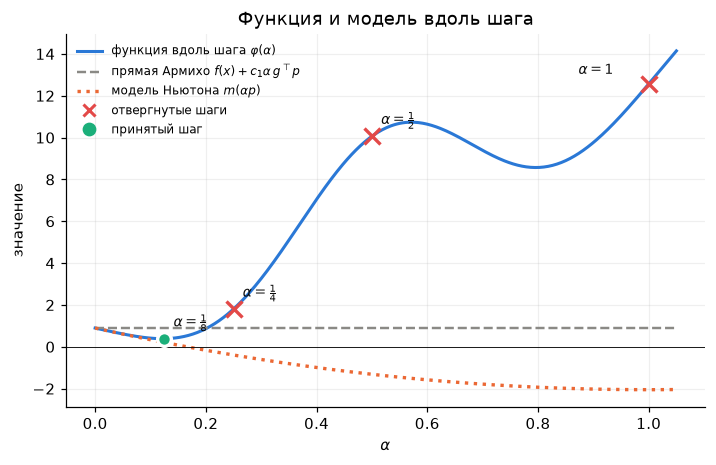

In [4]:
x1 = X0_VALLEY - np.linalg.solve(hess_valley(X0_VALLEY), grad_valley(X0_VALLEY))    # один шаг Ньютона из x0
g1, H1 = grad_valley(x1), hess_valley(x1)
p1 = -np.linalg.solve(H1, g1)
alpha1, tried1 = armijo(f_valley, x1, g1, p1)
print(f"x1 = {x1.round(3)}, f(x1) = {f_valley(x1):.3f};  полный шаг: f(x1 + p1) = {f_valley(x1 + p1):.2f} — в {f_valley(x1 + p1) / f_valley(x1):.0f} раз больше")
print(f"модель обещала f = {f_valley(x1) + 0.5 * g1 @ p1:.2f};  испытаны alpha = {tried1}: f =",
      [round(float(f_valley(x1 + t * p1)), 2) for t in tried1])
lam, Vec = np.linalg.eigh(H1)
print(f"собственные числа H1: {lam.round(3)};  направление меньшего: {Vec[:, 0].round(2)};  |p1| = {np.linalg.norm(p1):.2f}, p1 = {p1.round(3)}")
assert tried1 == [1.0, 0.5, 0.25, 0.125] and abs(f_valley(x1 + p1) - 12.57) < 0.01 and abs(lam[0] - 0.168) < 1e-3
plot_phi(f_valley, x1, g1, p1, tried1, H=H1); plt.show()

**Ответ (а).** Испытаны $\alpha=1,\ \tfrac12,\ \tfrac14$ — все отвергнуты: $f=12.57,\ 10.06,\ 1.81$ при $f(x_1)=0.90$; принят $\alpha=\tfrac18$, $f=0.39$. Полный шаг увеличивает $f$ в $14$ раз, а модель обещала $f=-2.05$ — отрицательное значение, невозможное для суммы квадратов. Причина — гессиан в $x_1=(0.022,\,0.833)$ почти вырожден: собственные числа $0.17$ и $6.0$, направление меньшего — почти чистая ось $u$. Вдоль неё модель — очень пологая парабола, и её минимум далеко: $\lVert p_1\rVert=5.92$, шаг почти целиком по $u$. На таком расстоянии $\cos u$ в третьей невязке давно перестал быть похожим на свою параболу, модель врёт, и Армихо укорачивает шаг до $\tfrac18$.

**(б) Картинка 2 (2 балла): чистый Ньютон против Ньютона с Армихо.** Запустите `newton` из $x_0$ дважды: с `line_search=False` и с `line_search=True`. Посчитайте для каждого число итераций, сколько раз $f$ выросла за шаг и максимум $f$ на пути. Нарисуйте пути — `plot_paths_valley([path_pure, path_armijo], labels)`, слева весь путь, справа окрестность минимума, — и расстояние до минимума $f(x_k)-f^\ast$ по итерациям: `plot_values(..., f_star=F_STAR_VALLEY)` ($f^\ast=0.0727$ — значение в минимуме; его вычитаем, иначе кривая упрётся в $0.07$, а не в ноль). Посчитайте $\lambda_{\min}$ (наименьшее собственное число гессиана) в точках обоих путей.

Ответьте: куда уходит чистый Ньютон и почему $f$ у него растёт? Что означает $\lambda_{\min}<0$ для модели и куда тогда ведёт шаг Ньютона? Почему у Ньютона с Армихо $f$ убывает на каждом шаге?

*Полный балл:* обе картинки; числа итераций, подъёмов и максимума; объяснение подъёмов через $\lambda_{\min}$ на пути и монотонности — через условие Армихо. *Половина:* запуски и картинки без объяснения.

чистый Ньютон   : итераций 22, f выросла раз: 8, максимум f =  2908.5, x* = [1.2496 0.2631]
Ньютон с Армихо : итераций  6, f выросла раз: 0, максимум f =   253.0, x* = [1.2496 0.2631]
самая далёкая точка чистого Ньютона: [-54.6 -16.3]
lambda_min на пути чистого Ньютона: [  6.    0.2   0.1   5.3   3.3 -25.5   0.7   2.5   1.1 -13.4   0.3 -10.
   0.3  -4.2   1.1   2.3   0.9   2.2   0.8   1.1   1.    1.    1. ]
lambda_min на пути с Армихо:        [6.   0.17 1.23 0.96 0.96 0.96 0.96]
в конце: f - f* = 3.4e-15 и 2.9e-15


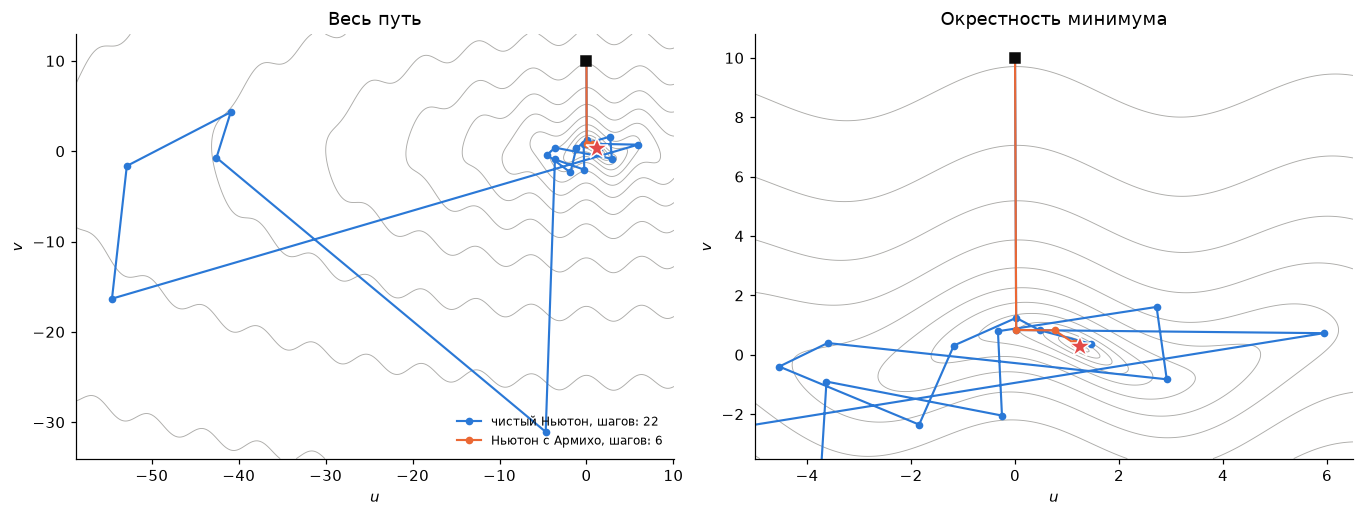

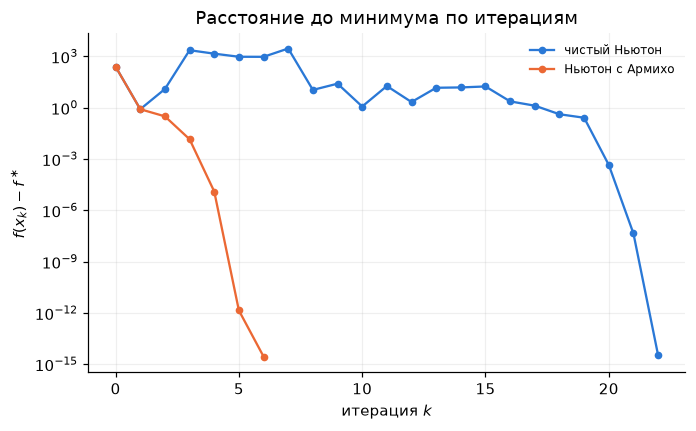

In [5]:
x_pure, k_pure, path_pure = newton(f_valley, grad_valley, hess_valley, X0_VALLEY, line_search=False)
x_arm, k_arm, path_arm = newton(f_valley, grad_valley, hess_valley, X0_VALLEY, line_search=True)
f_pure = np.array([f_valley(x) for x in path_pure]); f_arm = np.array([f_valley(x) for x in path_arm])
for name, k, fv, x in (("чистый Ньютон", k_pure, f_pure, x_pure), ("Ньютон с Армихо", k_arm, f_arm, x_arm)):
    print(f"{name:16s}: итераций {k:2d}, f выросла раз: {int(np.sum(np.diff(fv) > 0))}, максимум f = {fv.max():7.1f}, x* = {x.round(4)}")
print("самая далёкая точка чистого Ньютона:", path_pure[np.argmax(np.abs(path_pure[:, 0]))].round(1))
print("lambda_min на пути чистого Ньютона:", np.round([np.linalg.eigvalsh(hess_valley(x))[0] for x in path_pure], 1))
print("lambda_min на пути с Армихо:       ", np.round([np.linalg.eigvalsh(hess_valley(x))[0] for x in path_arm], 2))
print(f"в конце: f - f* = {f_pure[-1] - F_STAR_VALLEY:.1e} и {f_arm[-1] - F_STAR_VALLEY:.1e}")
assert (k_pure, k_arm, int(np.sum(np.diff(f_pure) > 0))) == (22, 6, 8) and abs(f_pure.max() - 2908.5) < 1
plot_paths_valley([path_pure, path_arm], ["чистый Ньютон", "Ньютон с Армихо"]); plt.show()
plot_values([f_pure, f_arm], ["чистый Ньютон", "Ньютон с Армихо"], f_star=F_STAR_VALLEY); plt.show()

**Ответ (б).** Чистый Ньютон делает $22$ итерации, $f$ растёт $8$ раз, максимум $2908$; путь уходит до $u=-55$ и только с $16$-й итерации возвращается к минимуму. Ньютон с Армихо — $6$ итераций, $f$ убывает на каждом шаге: $253\to0.90\to0.39\to0.087\to0.073$; на правой картинке $f-f^\ast$ у обоих методов в конце падает ниже $10^{-12}$ — сходимость квадратичная, только чистый Ньютон приходит к ней через $16$ лишних итераций. На пути чистого Ньютона $\lambda_{\min}$ то почти нулевой ($0.17$, $0.08$ — модель почти плоская, шаг огромный), то отрицательный (до $-25.5$): тогда модель — седло, и шаг Ньютона ведёт в её стационарную точку, которая не минимум, — $f$ может вырасти. Армихо принимает шаг, только если $f$ уменьшилась не меньше чем на $c_1\alpha\lvert g^\top p\rvert>0$, поэтому подъёмов нет; на его пути гессиан положительно определён ($\lambda_{\min}\ge0.17$), и направление Ньютона всегда ведёт вниз.

## Задача 2. Производные: повторение лекции 7 (5 баллов)

Эта задача решается на бумаге, кода писать не нужно. Ответы — в markdown-ячейках: оценки, таблицы и короткие пояснения. Ячейка с CasADi после условий считает точные значения, с которыми надо свериться.

**(а) Две ошибки разности (2 балла).** Функция $f(u)=e^u$ в точке $u=0$; её производная $f'(0)=1$ известна точно. Прямая разность

$$
D_+(h)=\frac{f(u+h)-f(u)}{h}
$$

ошибается по двум причинам (конспект §2.3–2.5): **усечение** — формула неточна при конечном $h$, ошибка $\approx\tfrac h2\lvert f''(u)\rvert$; **округление** — два близких значения $f$ известны лишь с точностью $\varepsilon\lvert f\rvert$, и после деления на $h$ ошибка $\approx 2\varepsilon\lvert f(u)\rvert/h$, где $\varepsilon\approx2.2\cdot10^{-16}$.

Для каждого из трёх шагов $h=10^{-1}$, $10^{-8}$, $10^{-12}$ оцените обе ошибки по этим формулам, скажите, какая из них преобладает, и назовите порядок общей ошибки. Затем найдите шаг $h^\ast$, при котором ошибки равны, и порядок наименьшей достижимой ошибки. Сверьте с ячейкой ниже.

*Полный балл:* три строки «$h$ — усечение — округление — что преобладает — ошибка»; $h^\ast$ с выводом из равенства ошибок; порядок наименьшей ошибки. *Половина:* порядки ошибок названы, но без объяснения причины.

In [6]:
# самопроверка (а): фактические ошибки прямой разности для f(u) = exp(u) в точке 0 и оценка h* из конспекта
f_exp = lambda u: np.exp(u)
for h in (1e-1, 1e-8, 1e-12):
    print(f"h = {h:.0e}:  D_+(h) = {(f_exp(h) - f_exp(0.0)) / h:.10f},  ошибка {abs((f_exp(h) - f_exp(0.0)) / h - 1.0):.1e}")
eps = np.finfo(float).eps
print(f"eps = {eps:.1e};  h* = 2 sqrt(eps |f| / |f''|) = {2 * np.sqrt(eps):.1e},  ошибка при h*: {abs((f_exp(2 * np.sqrt(eps)) - 1.0) / (2 * np.sqrt(eps)) - 1.0):.1e}")

h = 1e-01:  D_+(h) = 1.0517091808,  ошибка 5.2e-02
h = 1e-08:  D_+(h) = 0.9999999939,  ошибка 6.1e-09
h = 1e-12:  D_+(h) = 1.0000889006,  ошибка 8.9e-05
eps = 2.2e-16;  h* = 2 sqrt(eps |f| / |f''|) = 3.0e-08,  ошибка при h*: 1.5e-08


**Ответ (а).** Здесь $f=f''=1$, поэтому усечение $\approx h/2$, округление $\approx2\varepsilon/h=4.4\cdot10^{-16}/h$.

| $h$ | усечение $\tfrac h2$ | округление $2\varepsilon/h$ | преобладает | ошибка |
|---|---|---|---|---|
| $10^{-1}$ | $5\cdot10^{-2}$ | $4\cdot10^{-15}$ | усечение | $\sim5\cdot10^{-2}$ (факт: $5.2\cdot10^{-2}$) |
| $10^{-8}$ | $5\cdot10^{-9}$ | $4\cdot10^{-8}$ | округление, но обе одного порядка | $\sim10^{-8}$ (факт: $6\cdot10^{-9}$) |
| $10^{-12}$ | $5\cdot10^{-13}$ | $4\cdot10^{-4}$ | округление | $\sim10^{-4}$ (факт: $9\cdot10^{-5}$) |

Ошибки равны при $\tfrac h2=\tfrac{2\varepsilon}{h}$, то есть $h^\ast=2\sqrt{\varepsilon}\approx3\cdot10^{-8}$; обе ошибки там $\approx h^\ast/2\approx1.5\cdot10^{-8}$, так что лучшее, что даёт прямая разность, — около $10^{-8}$, восемь верных знаков из шестнадцати. Уменьшать $h$ дальше бесполезно: ошибка округления растёт как $1/h$.

**(б) Прямой и обратный режим для одной функции (3 балла).** Функция

$$
f(x_1,x_2)=x_1\,e^{x_1x_2}+x_2^2
$$

вычисляется программой из пяти строк:

$$
v_1=x_1x_2,\qquad v_2=e^{v_1},\qquad v_3=x_1v_2,\qquad v_4=x_2^2,\qquad f=v_3+v_4 .
$$

Точка — $(x_1,x_2)=(1,\,0.5)$. Обратите внимание: $x_1$ используется в двух строках ($v_1$ и $v_3$), $x_2$ тоже ($v_1$ и $v_4$).

1. **Прямой режим (1.5 балла).** Как в конспекте §3.2, запишите таблицу «программа | её производная по $x_2$»: в левой колонке пять строк со значениями, в правой — $\dot x_1$, $\dot x_2$ и $\dot v_1,\dots,\dot v_4$, $\dot f$ с числами (четыре знака). Получите $\partial f/\partial x_2$.
2. **Обратный режим (1.5 балла).** Как в §4.1, пройдите ту же программу снизу вверх: $\bar f=1$, затем $\bar v_4$, $\bar v_3$, $\bar v_2$, $\bar v_1$ и $\bar x_1$, $\bar x_2$ — таблица «строка программы | сложная производная | число». Получите обе компоненты градиента за один проход и укажите, в каких строках доли складываются и почему.

Сверьте $\partial f/\partial x_2$ из обоих пунктов между собой и с ячейкой ниже.

*Полный балл:* обе таблицы с верными числами; градиент совпадает с CasADi; названы два места сложения долей ($\bar x_1$ из $v_1$ и $v_3$, $\bar x_2$ из $v_1$ и $v_4$). *Половина:* одна таблица верна.

In [7]:
# самопроверка (б): значения строк программы и точный градиент CasADi в точке (1, 0.5)
u1, u2 = 1.0, 0.5                                   # точка (x1, x2) = (1, 0.5)
v1 = u1 * u2; v2 = np.exp(v1); v3 = u1 * v2; v4 = u2 ** 2
print(f"v1 = {v1:.4f}, v2 = {v2:.4f}, v3 = {v3:.4f}, v4 = {v4:.4f}, f = {v3 + v4:.4f}")
_y = ca.SX.sym("y", 2)
_, grad_b, _ = casadi_derivatives(_y[0] * ca.exp(_y[0] * _y[1]) + _y[1] ** 2, _y)
print("градиент CasADi в (1, 0.5):", grad_b(np.array([u1, u2])).round(4), "  — с ним сверяйте таблицы")

v1 = 0.5000, v2 = 1.6487, v3 = 1.6487, v4 = 0.2500, f = 1.8987
градиент CasADi в (1, 0.5): [2.4731 2.6487]   — с ним сверяйте таблицы


**Ответ (б).** В точке $(1,\,0.5)$: $v_1=0.5$, $v_2=e^{0.5}=1.6487$, $v_3=1.6487$, $v_4=0.25$, $f=1.8987$.

**Прямой режим, производная по $x_2$** ($\dot x_1=0$, $\dot x_2=1$):

| Программа | Её производная по $x_2$ |
|---|---|
| $x_1=1,\quad x_2=0.5$ | $\dot x_1=0,\quad \dot x_2=1$ |
| $v_1=x_1x_2=0.5$ | $\dot v_1=\dot x_1\,x_2+x_1\,\dot x_2=0+1=1$ |
| $v_2=e^{v_1}=1.6487$ | $\dot v_2=e^{v_1}\,\dot v_1=1.6487$ |
| $v_3=x_1v_2=1.6487$ | $\dot v_3=\dot x_1\,v_2+x_1\,\dot v_2=0+1.6487=1.6487$ |
| $v_4=x_2^2=0.25$ | $\dot v_4=2x_2\,\dot x_2=1$ |
| $f=v_3+v_4=1.8987$ | $\dot f=\dot v_3+\dot v_4=2.6487$ |

$\partial f/\partial x_2=2.6487$; по формуле $x_1^2e^{x_1x_2}+2x_2=1.6487+1$ — совпало.

**Обратный режим, снизу вверх** ($\bar f=1$):

| Строка программы | Сложная производная | Число |
|---|---|---|
| $f=v_3+v_4$ | $\bar v_3=\bar f\cdot1,\qquad \bar v_4=\bar f\cdot1$ | $\bar v_3=1,\quad \bar v_4=1$ |
| $v_4=x_2^2$ | $\bar x_2\mathrel{+}=\bar v_4\cdot2x_2$ | $\bar x_2=1$ (первая доля) |
| $v_3=x_1v_2$ | $\bar x_1\mathrel{+}=\bar v_3\cdot v_2,\qquad \bar v_2=\bar v_3\cdot x_1$ | $\bar x_1=1.6487$ (первая доля), $\bar v_2=1$ |
| $v_2=e^{v_1}$ | $\bar v_1=\bar v_2\cdot e^{v_1}$ | $\bar v_1=1.6487$ |
| $v_1=x_1x_2$ | $\bar x_1\mathrel{+}=\bar v_1\cdot x_2,\qquad \bar x_2\mathrel{+}=\bar v_1\cdot x_1$ | $\bar x_1=1.6487+0.8244=2.4731,\quad \bar x_2=1+1.6487=2.6487$ |

$\nabla f(1,\,0.5)=(2.4731,\ 2.6487)$ — обе компоненты за один проход; $\partial f/\partial x_2$ совпала с прямым режимом и с CasADi. Доли складываются там, где у величины два потребителя: $x_1$ входит в $v_1$ и в $v_3$, поэтому $\bar x_1$ собирается из двух строк ($1.6487$ от $v_3$ и $0.8244$ от $v_1$); $x_2$ входит в $v_1$ и в $v_4$ — $\bar x_2=1+1.6487$. Это та же сумма по путям, что в скобке правила сложной функции: $f$ зависит от $x_1$ и напрямую через $v_3$, и через $v_1\to v_2\to v_3$.

## Бонус (+2 балла). Доверительная область на той же функции

**Главная идея.** Доверительная область делает наоборот по сравнению с линейным поиском: сначала решает, в каком радиусе $\Delta$ модели можно верить, и берёт лучшую точку модели в круге $\lVert p\rVert\le\Delta$. Радиус настраивается сам — по тому, насколько модель угадала:

$$
\rho_k=\frac{f(x_k)-f(x_k+p_k)}{m_k(0)-m_k(p_k)}=\frac{\text{фактическое уменьшение}}{\text{обещанное моделью}},\qquad m_k(0)-m_k(p_k)=-\Big(g_k^\top p_k+\tfrac12\,p_k^\top B_kp_k\Big),
$$

где $B_k=\nabla^2f(x_k)$. Лучшую точку модели в круге находит готовая `tr_exact(g, B, Delta)` (конспект §3.3).

Напишите `trust_region(f, grad, hess, x0, solve_sub, Delta=1.0, Delta_max=10.0, eta=0.1, tol=1e-6, maxit=1000)` — цикл по алгоритму конспекта §3.2. Для $k=0,1,2,\dots$:

1. $g_k=\nabla f(x_k)$, $B_k=\nabla^2f(x_k)$; если $\lVert g_k\rVert\le10^{-6}$ — стоп;
2. $p_k$ = `solve_sub(g_k, B_k, Delta_k)`;
3. $\rho_k$ — по формуле выше (одно новое значение $f$);
4. радиус: при $\rho_k<\tfrac14$ — $\Delta_{k+1}=\Delta_k/4$; при $\rho_k>\tfrac34$ и шаге на границе ($\lVert p_k\rVert\ge0.99\,\Delta_k$) — $\Delta_{k+1}=\min(2\Delta_k,\ \Delta_{\max})$; иначе $\Delta_{k+1}=\Delta_k$;
5. шаг: при $\rho_k>\eta$ — $x_{k+1}=x_k+p_k$ (принят), иначе $x_{k+1}=x_k$ (отвергнут).

Итерация — один проход шагов 1–5, отвергнутые тоже считаются. Верните `(x, число итераций, путь, история)`: путь — массив принятых точек, начиная с $x_0$; история — список `(x_k, p_k, Delta_k, rho_k, принят)` по всем итерациям, его читает рисовальщик `plot_tr`.

**(а) Картинка 3 (1 балл): как дышит радиус.** Ячейка после вашей функции запустит её с `tr_exact` на «косинусной долине» из того же старта $x_0=(0,\,10)$, что в задаче 1, — должно получиться $11$ итераций и $2$ отвергнутых шага — и нарисует картинку: слева путь, круги $\Delta_k$ и отвергнутые пробные точки, справа $\Delta_k$ и $\rho_k$ по итерациям. Ответьте по ней: что делает радиус на первых итерациях и почему; на каких итерациях шаги отвергнуты, что там происходит с $f$ и чему равно $\rho_k$, что после каждого отказа делает радиус; почему у решения радиус больше не мешает.

*Балл:* проверка проходит и картинка — $0.5$; ответ по картинке — $0.5$. Бонус необязателен: если пропускаете, ячейки бонуса оставьте как есть.

In [8]:
def trust_region(f, grad, hess, x0, solve_sub, Delta=1.0, Delta_max=10.0, eta=0.1, tol=1e-6, maxit=1000):
    """Доверительная область (конспект §3.2). Возвращает (x, итераций, путь, история [(x_k, p_k, Delta_k, rho_k, принят)])."""
    x = np.asarray(x0, float).copy(); fx = f(x); path = [x.copy()]; hist = []
    for k in range(maxit):
        g = grad(x)
        if np.linalg.norm(g) <= tol:                               # 1. стоп
            return x, k, np.array(path), hist
        B = hess(x)
        p = solve_sub(g, B, Delta)                                  # 2. подзадача
        f_new = f(x + p)
        rho = (fx - f_new) / -(g @ p + 0.5 * p @ B @ p)             # 3. фактическое / обещанное
        hist.append((x.copy(), p.copy(), Delta, rho, rho > eta))
        if rho < 0.25:                                              # 4. радиус
            Delta = Delta / 4
        elif rho > 0.75 and np.linalg.norm(p) >= 0.99 * Delta:
            Delta = min(2 * Delta, Delta_max)
        if rho > eta:                                               # 5. принять шаг или остаться
            x = x + p; fx = f_new; path.append(x.copy())
    return x, maxit, np.array(path), hist

бонус (а): проверка ok;  итераций 11, отвергнуто 2, принятых шагов 9
  k =  0: x_k = ( 0.000, 10.000), f =  253.000, Delta = 1.00, |p| = 1.000, rho =   1.00, принят, f(x_k + p_k) =  200.994, lambda_min =  6.00
  k =  1: x_k = ( 0.011,  9.000), f =  200.994, Delta = 2.00, |p| = 2.000, rho =   1.00, принят, f(x_k + p_k) =  114.989, lambda_min =  6.00
  k =  2: x_k = ( 0.022,  7.000), f =  114.989, Delta = 4.00, |p| = 4.000, rho =   1.00, принят, f(x_k + p_k) =   14.969, lambda_min =  6.00
  k =  3: x_k = ( 0.044,  3.000), f =   14.969, Delta = 8.00, |p| = 2.173, rho =   1.00, принят, f(x_k + p_k) =    0.784, lambda_min =  5.99
  k =  4: x_k = ( 0.134,  0.829), f =    0.784, Delta = 8.00, |p| = 4.606, rho =  -2.87, ОТКАЗ , f(x_k + p_k) =    7.186, lambda_min =  0.21
  k =  5: x_k = ( 0.134,  0.829), f =    0.784, Delta = 2.00, |p| = 2.000, rho =  -2.15, ОТКАЗ , f(x_k + p_k) =    4.057, lambda_min =  0.21
  k =  6: x_k = ( 0.134,  0.829), f =    0.784, Delta = 0.50, |p| = 0.500, rho =   0.

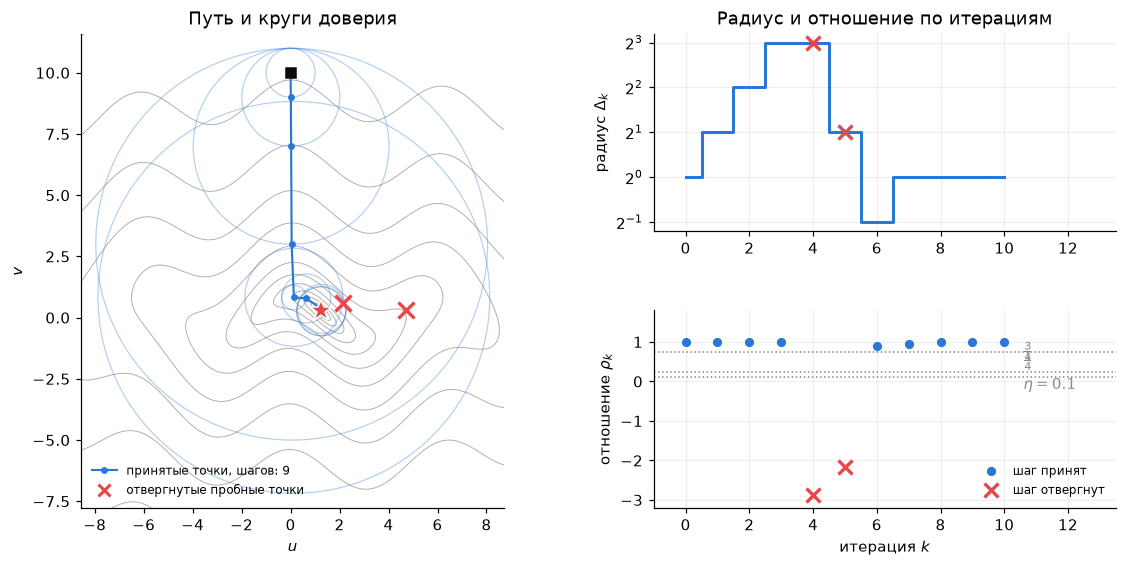

In [9]:
if "trust_region" in globals():         # бонус (а): выполняется, только если вы написали trust_region
    x_tr, k_tr, path_tr, hist_tr = trust_region(f_valley, grad_valley, hess_valley, X0_VALLEY, tr_exact)
    n_rej = sum(not h[4] for h in hist_tr)
    assert np.allclose(x_tr, X_STAR_VALLEY, atol=1e-3), f"метод должен прийти в минимум {X_STAR_VALLEY}, а пришёл в {x_tr}"
    assert (k_tr, n_rej) == (11, 2), \
        f"ожидается 11 итераций и 2 отвергнутых шага, у вас {k_tr} и {n_rej}: сверьте правила радиуса, порог «на границе» и счёт отвергнутых"
    print(f"бонус (а): проверка ok;  итераций {k_tr}, отвергнуто {n_rej}, принятых шагов {len(path_tr) - 1}")
    for k, (xk, pk, Dk, rk, ok) in enumerate(hist_tr):
        print(f"  k = {k:2d}: x_k = ({xk[0]:6.3f}, {xk[1]:6.3f}), f = {f_valley(xk):8.3f}, Delta = {Dk:4.2f}, |p| = {np.linalg.norm(pk):5.3f}, "
              f"rho = {rk:6.2f}, {'принят' if ok else 'ОТКАЗ '}, f(x_k + p_k) = {f_valley(xk + pk):8.3f}, lambda_min = {np.linalg.eigvalsh(hess_valley(xk))[0]:5.2f}")
    plot_tr(hist_tr, path_tr); plt.show()
else:
    print("бонус пропущен")

**Ответ (а).** Первые три шага ($k=0,1,2$) упираются в границу круга при $\rho\approx1$: модель угадывает, и радиус удваивается, $1\to2\to4\to8$, а $f$ падает $253\to201\to115\to15$. На $k=3$ при $\Delta=8$ точка Ньютона уже внутри круга ($\lVert p\rVert=2.2$), $\rho=1$, и метод приходит в $(0.13,\,0.83)$ — в ту же пологую область, что в задаче 1 ($\lambda_{\min}=0.21$). Здесь два отказа подряд: на $k=4$ шаг Ньютона длиной $4.6$ поднимает $f$ с $0.78$ до $7.19$, $\rho=-2.87$, радиус $8\to2$; на $k=5$ шаг на границе нового круга даёт $f=4.06$, $\rho=-2.15$, радиус $2\to0.5$. На $k=6$ шаг длиной $0.5$ принят ($\rho=0.89$), и радиус снова удвоен до $1$. Дальше $\rho\approx1$, а шаги $0.77$, $0.10$, $0.003$ короче радиуса: точка Ньютона внутри круга, подзадача возвращает чистый шаг Ньютона, радиус не мешает — сходимость квадратичная. Итого $11$ итераций, $9$ принятых шагов.

**(б) Картинка 4 (1 балл): три метода на одной функции.** Ячейка ниже запускает из $x_0$ чистый Ньютон, Ньютон с Армихо (ваш `armijo` из задачи 1) и вашу доверительную область, печатает для каждого число итераций, подъёмов $f$ и максимум $f$ и рисует все три пути на линиях уровня и $f(x_k)-f^\ast$ по итерациям. Ответьте: почему у доверительной области, как и у Армихо, $f$ не растёт ни разу; почему ей здесь нужно $11$ итераций против $6$ у Армихо; что общего у двух лекарств лекции 6 и чем они отличаются.

*Балл:* числа с картинок — $0.5$; объяснение — $0.5$.

чистый Ньютон         : итераций 22, f выросла раз: 8, максимум f =  2908.5
Ньютон с Армихо       : итераций  6, f выросла раз: 0, максимум f =   253.0
доверительная область : итераций 11, f выросла раз: 0, максимум f =   253.0
после первого шага Армихо: [0.022 0.833] ;  доверительная область после четырёх итераций: [0.134 0.829]


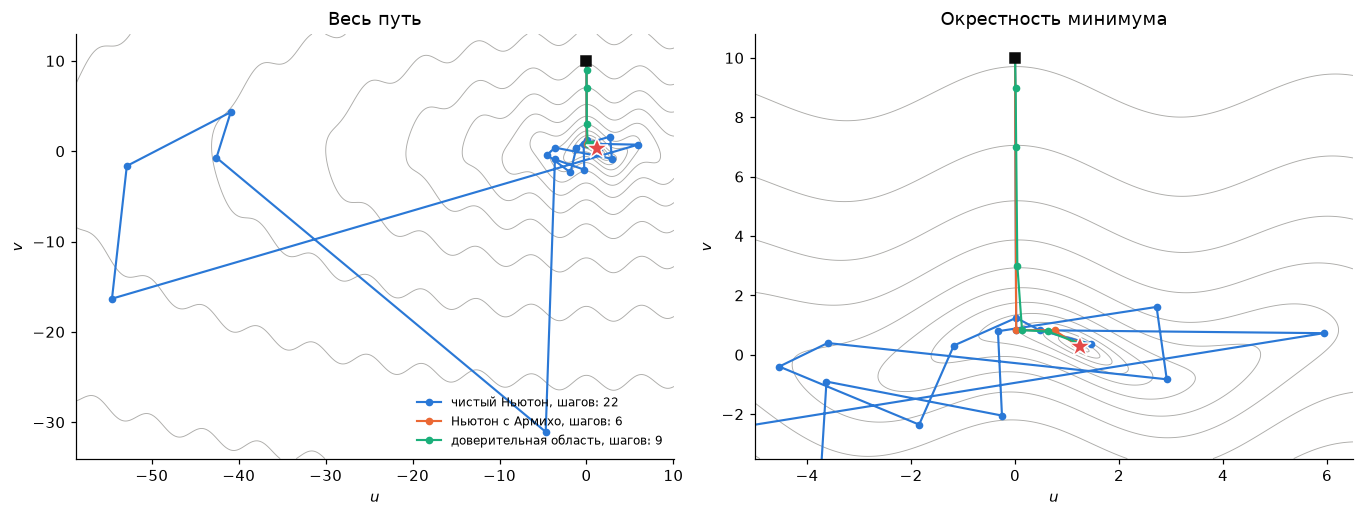

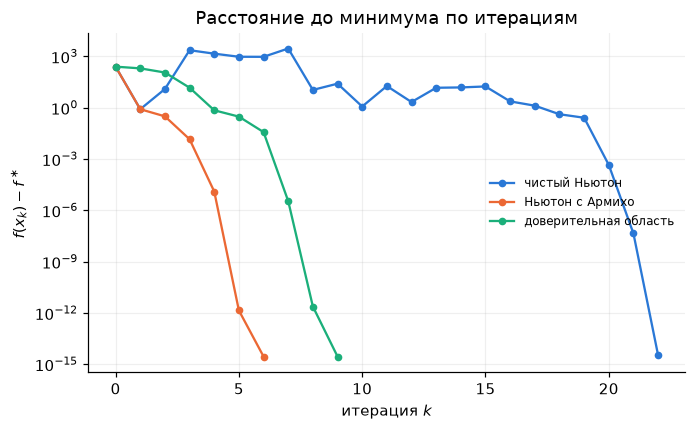

In [10]:
if "trust_region" in globals():         # бонус (б): три метода из одного старта
    x_p, k_p, path_p = newton(f_valley, grad_valley, hess_valley, X0_VALLEY, line_search=False)
    x_a, k_a, path_a = newton(f_valley, grad_valley, hess_valley, X0_VALLEY, line_search=True)
    x_t, k_t, path_t, hist_t = trust_region(f_valley, grad_valley, hess_valley, X0_VALLEY, tr_exact)
    paths = [path_p, path_a, path_t]; labels = ["чистый Ньютон", "Ньютон с Армихо", "доверительная область"]
    values = [np.array([f_valley(x) for x in P]) for P in paths]
    for lab, k, fv in zip(labels, (k_p, k_a, k_t), values):
        print(f"{lab:22s}: итераций {k:2d}, f выросла раз: {int(np.sum(np.diff(fv) > 0))}, максимум f = {fv.max():7.1f}")
    print("после первого шага Армихо:", path_a[1].round(3), ";  доверительная область после четырёх итераций:", path_t[4].round(3))
    plot_paths_valley(paths, labels); plt.show()
    plot_values(values, labels, f_star=F_STAR_VALLEY); plt.show()
else:
    print("бонус пропущен")

**Ответ (б).** Чистый Ньютон: $22$ итерации, $8$ подъёмов, максимум $f=2908$, путь уходит до $u=-55$. Ньютон с Армихо: $6$ итераций, подъёмов нет. Доверительная область: $11$ итераций ($2$ отказа), подъёмов нет, максимум — стартовые $253$. Оба лекарства проверяют шаг самой функцией: Армихо принимает $\alpha$, только если $f$ упала не меньше чем на $c_1\alpha\lvert g^\top p\rvert$, доверительная область — только если $\rho_k>\eta$, то есть $f$ действительно уменьшилась; поэтому ни у того, ни у другого подъёмов нет. Отличие — в том, что делается с шагом. Армихо берёт направление Ньютона и только укорачивает его: здесь оно всюду было спуском ($\lambda_{\min}\ge0.17$ на пути), первый же полный шаг из $x_0$ привёл в пологую область $(0.02,\,0.83)$ за одну итерацию, и хватило шести. Доверительная область ограничивает шаг кругом и на границе круга меняет само направление: на ту же дорогу ей нужны четыре итерации с радиусами $1,2,4,8$, потом два отказа в пологой области — итераций больше. Зато каждая отвергнутая попытка стоит одно вычисление $f$, а при индефинитном гессиане метод работает и там, где направление Ньютона не спуск и наш `newton` с Армихо остановился бы на `assert`.